# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


Пайплайн (последовательность шагов обработки) устроен так: сначала задаётся спецификация сцены — формальное описание того, что должно быть на картинке (форма, цвет, количество объектов, seed — начальное значение генератора случайных чисел, обеспечивающее воспроизводимость). Затем спецификация попадает в рендерер (процедурный отрисовщик) или в диффузионную модель, которая по текстовому описанию генерирует изображение. После этого полученные картинки проходят верификацию (проверку) с помощью VLM — vision-language model, то есть мультимодальной модели, которая «видит» изображение и отвечает на вопрос о нём. Если ответ модели расходится с меткой рендерера, пример отбраковывается на этапе фильтрации (filtering). Наконец, очищенный синтетический набор используется для downstream evaluation — нижележащей оценки, то есть обучения или проверки целевой модели на итоговой задаче.

Ключевое методологическое требование: синтетический тест не заменяет реальный. Синтетика проверяет, что модель выучила правило счёта в «чистом» домене (domain — предметная область, здесь «геометрические фигуры на белом фоне»), но она ничего не говорит о переносе на фотографии. Итоговые метрики качества снимаются только на отложенном реальном наборе, который модель никогда не видела. Второе требование — provenance (происхождение данных): для каждого примера должен быть зафиксирован источник, seed, спецификация, путь к файлу и контрольная сумма. Без этого синтетику нельзя воспроизвести, а значит нельзя и защитить результат.

**Пайплайн генерации и использования синтетических данных.**

Пайплайн (последовательность шагов обработки) устроен так: сначала задаётся спецификация сцены — формальное описание того, что должно быть на картинке (форма, цвет, количество объектов, seed — начальное значение генератора случайных чисел, обеспечивающее воспроизводимость). Затем спецификация попадает в рендерер (процедурный отрисовщик) или в диффузионную модель, которая по текстовому описанию генерирует изображение. После этого полученные картинки проходят верификацию (проверку) с помощью VLM — vision-language model, то есть мультимодальной модели, которая «видит» изображение и отвечает на вопрос о нём. Если ответ модели расходится с меткой рендерера, пример отбраковывается на этапе фильтрации (filtering). Наконец, очищенный синтетический набор используется для downstream evaluation — нижележащей оценки, то есть обучения или проверки целевой модели на итоговой задаче.

Ключевое методологическое требование: синтетический тест не заменяет реальный. Синтетика проверяет, что модель выучила правило счёта в «чистом» домене (domain — предметная область, здесь «геометрические фигуры на белом фоне»), но она ничего не говорит о переносе на фотографии. Итоговые метрики качества снимаются только на отложенном реальном наборе, который модель никогда не видела. Второе требование — provenance (происхождение данных): для каждого примера должен быть зафиксирован источник, seed, спецификация, путь к файлу и контрольная сумма. Без этого синтетику нельзя воспроизвести, а значит нельзя и защитить результат.

**Смеси данных и исследовательский вопрос.**

Обозначим $D_{real}$ — реальный обучающий набор, $D_{syn}$ — синтетический. Смесь задаётся выпуклой комбинацией $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$, где $\alpha \in [0,1]$ — доля синтетики в общем бюджете обучения. Важно, что бюджет (число обучающих примеров $N$) фиксирован: при увеличении $\alpha$ мы не добавляем примеры, а заменяем часть реальных синтетическими. Иначе сравнение было бы нечестным — модель с большим числом примеров почти всегда выигрывает, и непонятно, за счёт чего именно.

На фиксированном реальном тестовом наборе измеряется $Q(\alpha)$ — метрика качества (в лабораторной это accuracy, доля правильных ответов) как функция доли синтетики. Форма кривой $Q(\alpha)$ и есть предмет исследования: если она растёт от $\alpha=0$ к какому-то промежуточному значению, синтетика помогает; если монотонно падает — синтетика вредит из-за domain gap (разрыва между доменами); если имеет пик — есть оптимальная доля. В лабораторной мы смотрим четыре точки: $\alpha \in \{0, 0.25, 0.5, 0.75\}$.

**Дедупликация (duplicate filtering).**

Дубли в синтетике возникают естественно: если перебирать комбинации с повторами или генерировать с близкими seed, можно получить визуально почти одинаковые картинки. Дубли искажают распределение (модель переобучается на повторяющихся примерах) и завышают метрики. Поэтому дедупликация обязательна. Работает она на эмбеддингах (embedding — векторное представление изображения, полученное замороженной нейросетью, здесь ResNet18): для каждой пары картинок считается cosine similarity — косинусная близость, то есть косинус угла между векторами; значения близко к 1 означают, что изображения почти одинаковы. Пары с близостью выше порога (в лабораторной 0.98) помечаются как дубли, один из них отбрасывается. Помимо этого ловится точное совпадение по SHA-256 хешу пикселей — это дешёвая проверка на полные копии.


## Практический протокол

В полном (не отладочном) режиме лабораторная требует трёх вещей одновременно: реального тестового корпуса, реальной проверки синтетики мультимодальной моделью и обучения нескольких downstream-моделей — то есть моделей, решающих целевую задачу (здесь бинарная классификация «два объекта против трёх» по замороженным признакам). Убрать любой из этих элементов нельзя: без реального теста нет честной метрики, без VLM-проверки синтетика может содержать ошибки рендерера и неоднозначные сцены, без нескольких downstream-моделей невозможно сравнить доли смеси.

Процедурный рендерер (renderer — программа, рисующая изображение по формальному описанию, а не генеративная нейросеть) выбран именно потому, что он даёт полную воспроизводимость provenance: для каждой картинки известны seed, спецификация, координаты, цвета и контрольная сумма. Однако — и это принципиально — синтетические изображения ни при каких обстоятельствах не называются «реальными». Они живут в отдельном домене, и весь смысл эксперимента в том, чтобы измерить разрыв между доменами, а не замаскировать его.

Реальные фотографии и опубликованные человечески проверенные метки числа объектов (только классы «2» и «3», чтобы совпадало с синтетическим пространством) берутся из набора PixMo-Count: из validation-сплита формируется реальный train, из test-сплита — отложенный реальный test.

Мы проверяем, переносится ли навык счёта геометрических фигур на реальные объекты — людей, машины, животных на фотографиях. Это не тест распознавания кругов и квадратов; последнее проверялось бы на синтетическом тесте, который в этой работе играет вспомогательную роль.

In [1]:
from pathlib import Path
import json, os, random, time, hashlib
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)  # фиксируем все источники случайности

def save_json(name, data):
    (ARTIFACTS / name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

Рендерер получает на вход спецификацию (shape, color, count, seed) и возвращает изображение PIL. Требования этапа — фиксированные координаты (детерминированное размещение от seed) и отсутствие перекрытий между фигурами. Удобный приём — заранее нарезать холст на сетку ячеек, перемешать её локальным генератором от seed и взять первые count ячеек. Тогда перекрытия невозможны геометрически: центры разнесены минимум на шаг сетки, а радиус фигуры меньше половины шага. Палитра — словарь «имя цвета → RGB», чтобы спецификация была человекочитаемой и одинаково интерпретировалась рендерером, вопросом и манифестом

Все фигуры на картинке одинаковые — одна форма и один цвет, различается только их количество и расположение.

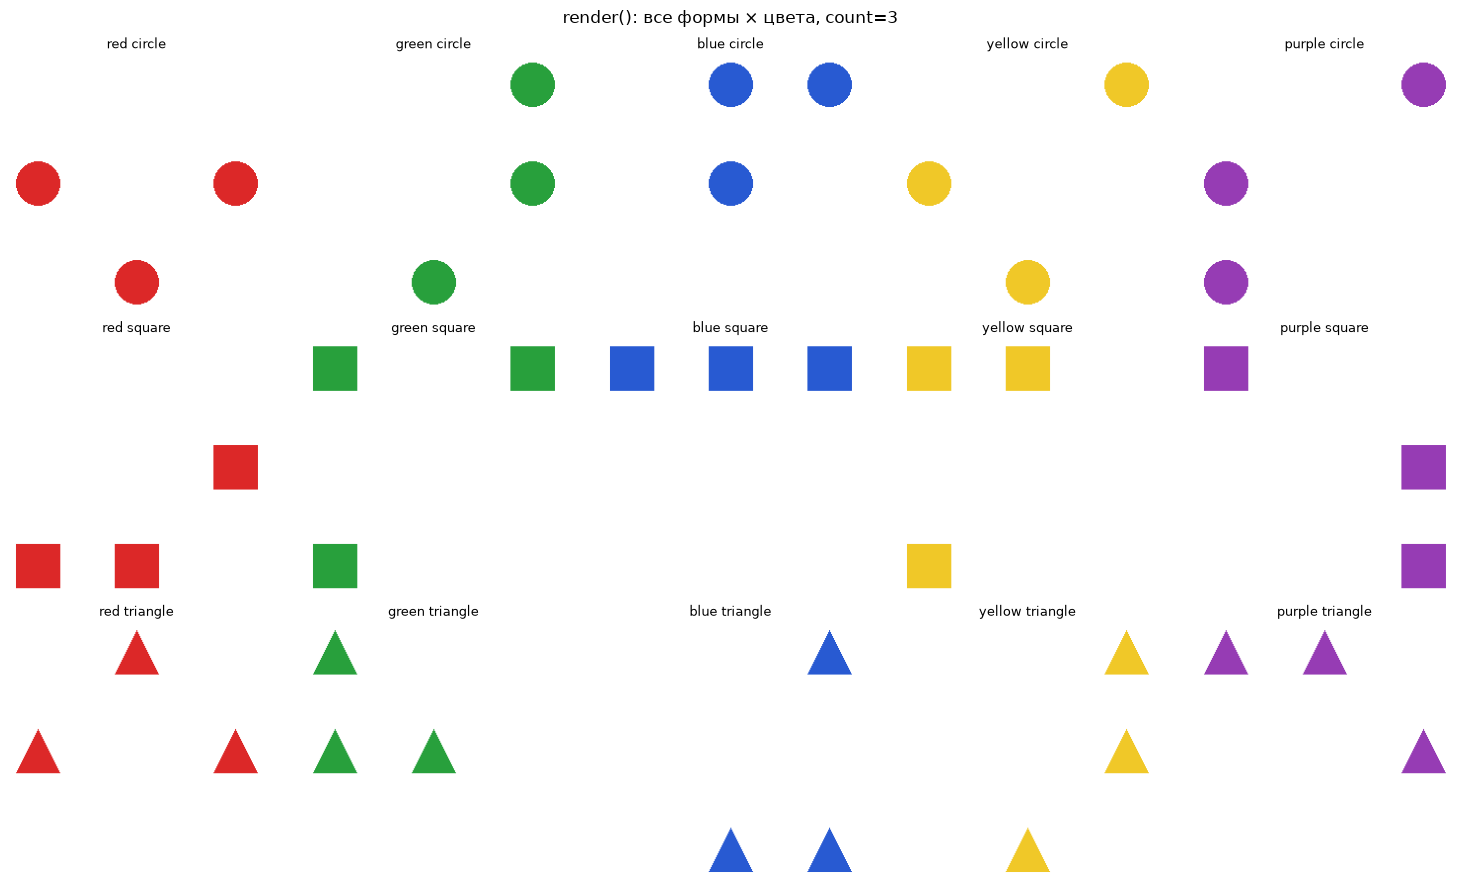

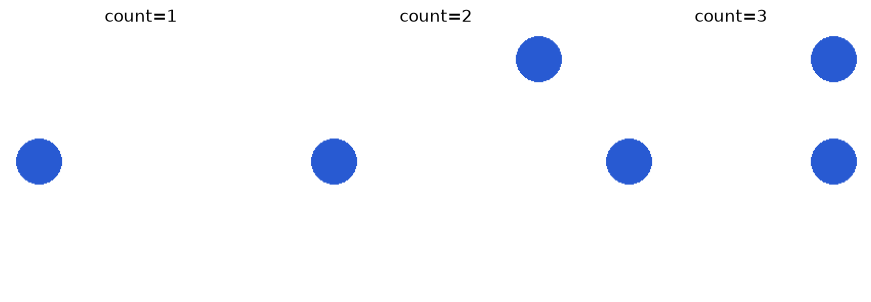

palette keys: ['red', 'green', 'blue', 'yellow', 'purple']


In [13]:
# --- Рендерер геометрических фигур: детерминированное размещение, без перекрытий ---
from PIL import Image, ImageDraw
import random
import math
import matplotlib.pyplot as plt

# Палитра: имя -> RGB. Имена используются и в спецификации, и в тексте вопроса.
PALETTE = {
    'red':    (220, 40, 40),
    'green':  (40, 160, 60),
    'blue':   (40, 90, 210),
    'yellow': (240, 200, 40),
    'purple': (150, 60, 180),
}
SHAPES = ['circle', 'square', 'triangle']

# Геометрия холста и сетки. Сетка 3x3 -> максимум 9 неперекрывающихся фигур.
IMG_SIZE = 256
MARGIN   = 28                      # отступ от края, чтобы фигуры не обрезались
RADIUS   = 22                      # радиус описанной окружности фигуры
STEP     = (IMG_SIZE - 2 * MARGIN) // 2  # шаг между центрами ячеек

def _cell_centers():
    """Центры 9 ячеек сетки 3x3 в фиксированном порядке."""
    return [(MARGIN + i * STEP, MARGIN + j * STEP)
            for i in range(3) for j in range(3)]

def render(spec):
    """spec: {'shape','color','count','seed'} -> PIL.Image (RGB, IMG_SIZE x IMG_SIZE)."""
    rng = random.Random(spec['seed'])            # локальный ГПСЧ: воспроизводимо от seed
    img = Image.new('RGB', (IMG_SIZE, IMG_SIZE), 'white')
    draw = ImageDraw.Draw(img)
    cells = _cell_centers()
    rng.shuffle(cells)                            # перемешиваем детерминированно
    centers = cells[:spec['count']]               # берём первые count ячеек
    color = PALETTE[spec['color']]
    for (cx, cy) in centers:
        if spec['shape'] == 'circle':
            draw.ellipse([cx-RADIUS, cy-RADIUS, cx+RADIUS, cy+RADIUS], fill=color)
        elif spec['shape'] == 'square':
            draw.rectangle([cx-RADIUS, cy-RADIUS, cx+RADIUS, cy+RADIUS], fill=color)
        elif spec['shape'] == 'triangle':
            draw.polygon([(cx, cy-RADIUS), (cx-RADIUS, cy+RADIUS), (cx+RADIUS, cy+RADIUS)],
                         fill=color)
        else:
            raise ValueError(f"unknown shape: {spec['shape']}")
    return img

# --- Проверка инварианта: попарные расстояния центров > 2*RADIUS ---
def assert_no_overlap(spec):
    rng = random.Random(spec['seed'])
    cells = _cell_centers(); rng.shuffle(cells)
    pts = cells[:spec['count']]
    for i in range(len(pts)):
        for j in range(i+1, len(pts)):
            d = math.dist(pts[i], pts[j])
            assert d > 2 * RADIUS, f'overlap in {spec}: d={d}'
    return True

# прогоняем инвариант по всем формам/цветам при count=2,3
for sh in SHAPES:
    for col in PALETTE:
        for n in (2, 3):
            assert_no_overlap({'shape': sh, 'color': col, 'count': n, 'seed': n})

# --- Визуализация: строки — формы, столбцы — цвета, отдельная фигура для count=3 ---
fig, axes = plt.subplots(len(SHAPES), len(PALETTE),
                         figsize=(3*len(PALETTE), 3*len(SHAPES)))
for r, sh in enumerate(SHAPES):
    for c, col in enumerate(PALETTE):
        spec = {'shape': sh, 'color': col, 'count': 3, 'seed': r*10 + c}
        axes[r][c].imshow(render(spec))
        axes[r][c].set_title(f'{col} {sh}', fontsize=9)
        axes[r][c].axis('off')
plt.suptitle('render(): все формы × цвета, count=3')
plt.tight_layout()
plt.show()

# --- Отдельно: как count влияет на картинку при одной форме/цвете ---
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, n in zip(axes, (1, 2, 3)):
    ax.imshow(render({'shape':'circle','color':'blue','count':n,'seed':7}))
    ax.set_title(f'count={n}'); ax.axis('off')
plt.tight_layout(); plt.show()

print('palette keys:', list(PALETTE))

### Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

Спецификация сцены — это кортеж (shape, color, count, seed), полностью определяющий изображение. Пространство сцен (scene space) — декартово произведение множеств форм, цветов и допустимых количеств. Мы перечисляем его детерминированно, присваивая каждому элементу уникальный id и seed = индекс. Такой перебор даёт три вещи: (а) воспроизводимость — по id всегда восстанавливается спецификация, (б) сбалансированность — каждая комбинация формы/цвета/количества встречается ровно один раз, (в) контролируемый размер — число сцен заранее известно и не зависит от случайности.

Почему count ∈ {2, 3}, а не {1, 2, 3}. В реальном наборе PixMo-Count мы берём человечески проверенные метки именно классов «2» и «3», чтобы синтетика и реальность имели общий набор меток. Если бы синтетика содержала класс «1», а реальность — нет (или наоборот), смешивание дало бы модели фиктивный класс и сломало бы downstream-классификатор. Класс «1» остаётся в рендерере как возможность, но в спецификацию для обучения не входит.

Размер пространства: 3 формы × 5 цветов × 2 количества = 30 сцен. Этого мало для полноценного обучения, но в полном режиме синтетика используется как добавка к 24 реальным примерам при фиксированном бюджете

сцен в пространстве: 30
      id  shape  color  count  seed
syn-0000 circle    red      2     0
syn-0001 circle    red      3     1
syn-0002 circle  green      2     2
syn-0003 circle  green      3     3
syn-0004 circle   blue      2     4
syn-0005 circle   blue      3     5
syn-0006 circle yellow      2     6
syn-0007 circle yellow      3     7
syn-0008 circle purple      2     8
syn-0009 circle purple      3     9
...
распределение count: {2: 15, 3: 15}
комбинаций (shape,color): 15


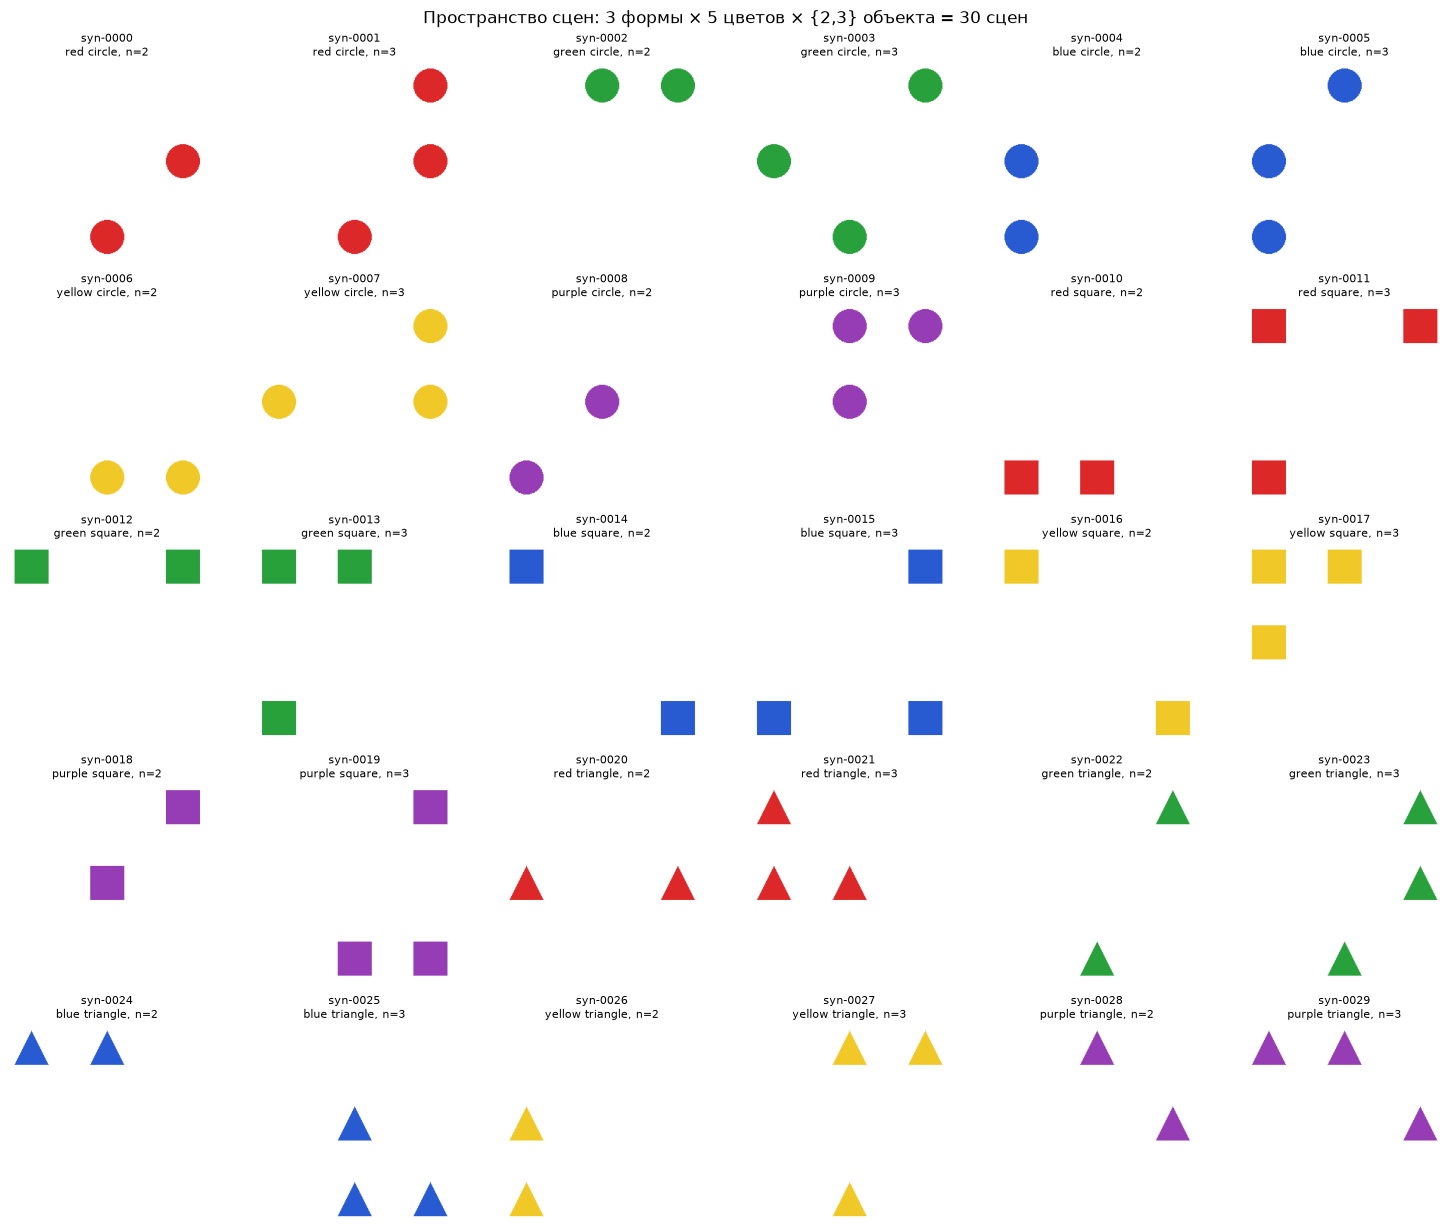

saved: artifacts\scene_space.jsonl


In [14]:
# --- Построение пространства сцен: все комбинации формы, цвета, количества ---
import json
from pathlib import Path
import pandas as pd

ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)

def build_scene_space(shapes, colors, counts):
    """Декартово произведение shapes × colors × counts.
    Каждой сцене — уникальный id и seed (= порядковый номер)."""
    specs = []
    idx = 0
    for sh in shapes:                 # фиксированный порядок обхода
        for col in colors:            # гарантирует детерминизм
            for n in counts:
                specs.append({
                    'id':    f'syn-{idx:04d}',
                    'shape': sh,
                    'color': col,
                    'count': n,
                    'seed':  idx,         # seed = индекс -> воспроизводимость
                })
                idx += 1
    return specs

# count={2,3} — общий класс с реальным PixMo-Count (там тоже только 2 и 3)
SCENES = build_scene_space(SHAPES, list(PALETTE), counts=(2, 3))
print(f'сцен в пространстве: {len(SCENES)}')

# --- Инварианты пространства: уникальность id/seed и полнота комбинаций ---
ids   = [s['id'] for s in SCENES]
seeds = [s['seed'] for s in SCENES]
assert len(set(ids))   == len(ids),   'id не уникальны'
assert len(set(seeds)) == len(seeds), 'seed не уникальны'
assert len(SCENES) == len(SHAPES) * len(PALETTE) * 2, 'пространство неполное'

# --- Таблица спецификаций (это и есть «предъявить спецификации») ---
df = pd.DataFrame(SCENES)
print(df.head(10).to_string(index=False))
print('...')
print(f'распределение count: {df["count"].value_counts().to_dict()}')
print(f'комбинаций (shape,color): {df.groupby(["shape","color"]).ngroups}')

# --- Визуализация: сетка картинок по всем 30 сценам ---
import matplotlib.pyplot as plt
fig, axes = plt.subplots(5, 6, figsize=(15, 12.5))
for ax, spec in zip(axes.ravel(), SCENES):
    ax.imshow(render(spec))
    ax.set_title(f"{spec['id']}\n{spec['color']} {spec['shape']}, n={spec['count']}",
                 fontsize=8)
    ax.axis('off')
plt.suptitle('Пространство сцен: 3 формы × 5 цветов × {2,3} объекта = 30 сцен')
plt.tight_layout()
plt.show()

# --- Сохраняем спецификации как отдельный артефакт ---
(ARTIFACTS / 'scene_space.jsonl').write_text(
    ''.join(json.dumps(s, ensure_ascii=False) + '\n' for s in SCENES))
print('saved:', ARTIFACTS / 'scene_space.jsonl')

### Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

На этом этапе каждая спецификация превращается в материальный пример: файл изображения на диске плюс пара «вопрос — ответ». Ключевое требование — вопрос должен быть однозначным и не требовать от модели знания нашей внутренней палитры. Если спросить просто «How many objects?», модель может ответить числом, но не будет ясно, считает ли она фигуры или что-то ещё; если спросить «How many blue circles?», ответ проверяем и по пикселям, и по метке рендерера. Поэтому формулировка вопроса строится из спецификации: shape и color подставляются явно, а count уходит в ответ.

Вторая тонкость — формат ответа. Мы фиксируем инструкцию «Answer with one integer», чтобы VLM не писала «There are three circles» и не ломала парсинг. На этапе верификации мы всё равно будем извлекать первое целое регуляркой (на случай, если модель проигнорирует инструкцию), но чем чище формулировка, тем меньше шума.

Ответ здесь — не ответ модели, а эталон (ground truth). Мы его знаем заранее, потому что сцену нарисовал рендерер по спецификации: если в спецификации count=3, то правильный ответ — «3», и никакая модель для этого не нужна. Это метка, с которой потом будем сравнивать ответы VLM и обучать downstream-классификатор. Так же устроена любая разметка: в датасете лежит пара «вход — правильный ответ»

изображений сохранено: 30
      id                                                        question answer
syn-0002    How many green circles are visible? Answer with one integer.      2
syn-0028 How many purple triangles are visible? Answer with one integer.      2
syn-0013    How many green squares are visible? Answer with one integer.      3
syn-0010      How many red squares are visible? Answer with one integer.      2
syn-0026 How many yellow triangles are visible? Answer with one integer.      2
уникальных вопросов: 15
распределение ответов: {'2': 15, '3': 15}


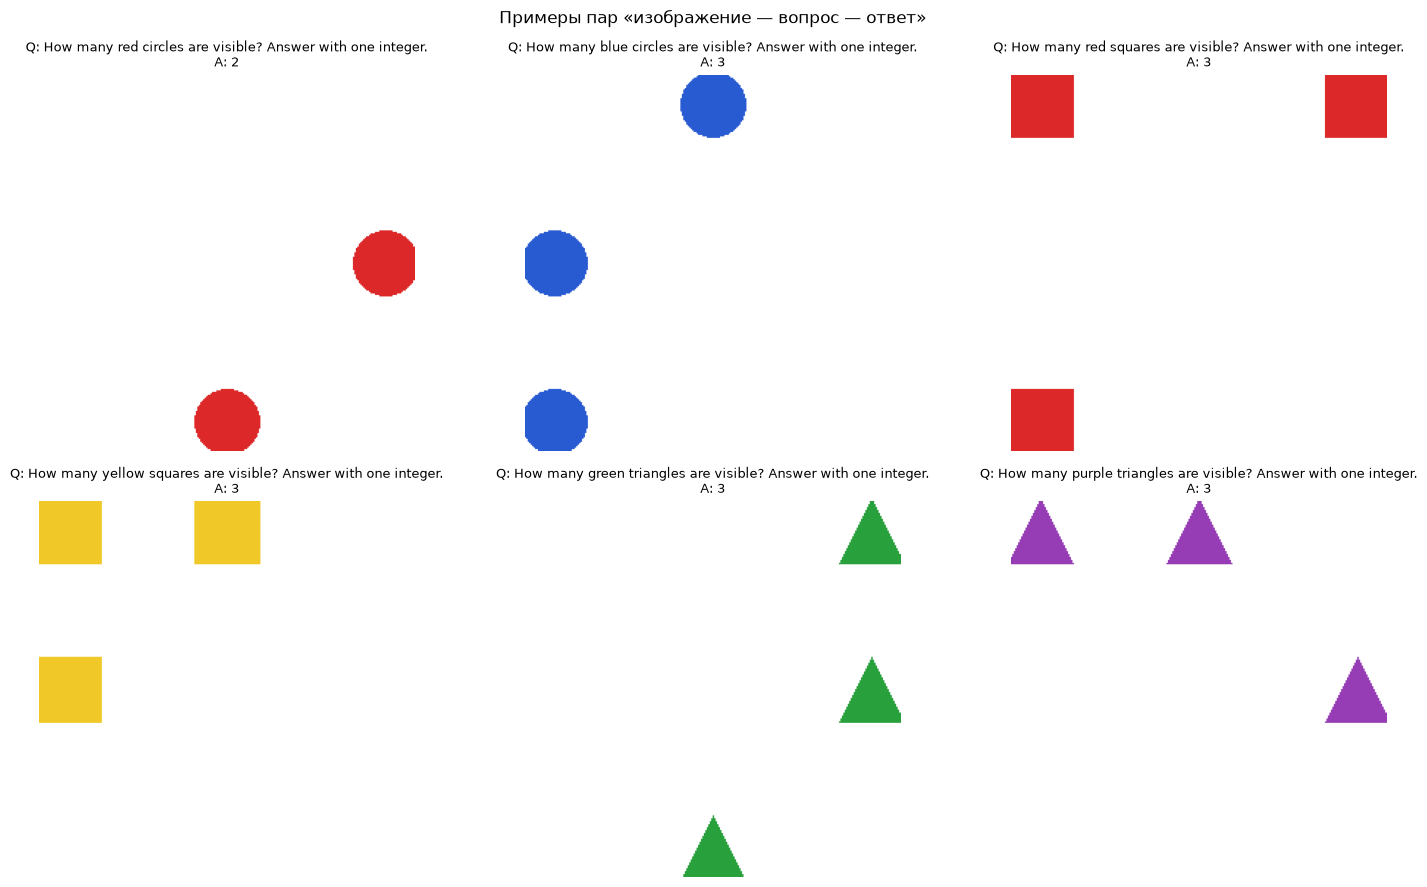

saved: artifacts\synthetic_qa.jsonl


In [15]:
# --- Сохранение изображений и пар (вопрос, ответ) для каждой сцены ---
import json
from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

IMG_DIR = Path('data/lab12/synthetic')
IMG_DIR.mkdir(parents=True, exist_ok=True)

def scene_to_qa(spec):
    """Формулируем вопрос из спецификации; ответ = count.
    Вопрос однозначен: явно указаны цвет и форма, ответ — одно целое."""
    question = (f"How many {spec['color']} {spec['shape']}s are visible? "
                f"Answer with one integer.")
    return question, str(spec['count'])

# --- Генерируем и сохраняем изображения, собираем записи ---
synthetic_records = []
for spec in SCENES:
    path = IMG_DIR / f"{spec['id']}.png"          # имя из id -> трассируемость
    if not path.exists():                          # не перезаписываем без нужды
        render(spec).save(path, format='PNG')      # PNG без потерь
    question, answer = scene_to_qa(spec)
    synthetic_records.append({
        **spec,                                     # id, shape, color, count, seed
        'image':    str(path.resolve()),
        'question': question,
        'answer':   answer,
    })

# --- Проверка целостности: файл существует, читается, размер корректный ---
for rec in synthetic_records:
    with Image.open(rec['image']) as im:
        im.verify()
    assert Path(rec['image']).stat().st_size > 0
print(f'изображений сохранено: {len(synthetic_records)}')

# --- Таблица пар (вопрос, ответ) — предъявляем как артефакт этапа ---
df_qa = pd.DataFrame([{'id': r['id'], 'question': r['question'], 'answer': r['answer']}
                      for r in synthetic_records])
print(df_qa.sample(5, random_state=0).to_string(index=False))
print('уникальных вопросов:', df_qa['question'].nunique())
print('распределение ответов:', df_qa['answer'].value_counts().to_dict())

# --- Визуализация: несколько примеров с вопросом и ответом над картинкой ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
picks = [0, 5, 11, 17, 23, 29]                    # разные формы/цвета/count
for ax, k in zip(axes.ravel(), picks):
    rec = synthetic_records[k]
    ax.imshow(Image.open(rec['image']))
    ax.set_title(f"Q: {rec['question']}\nA: {rec['answer']}", fontsize=9)
    ax.axis('off')
plt.suptitle('Примеры пар «изображение — вопрос — ответ»')
plt.tight_layout()
plt.show()

# --- Сохраняем пары в отдельный файл (промежуточный артефакт) ---
QA_PATH = ARTIFACTS / 'synthetic_qa.jsonl'
QA_PATH.write_text(
    ''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in synthetic_records))
print('saved:', QA_PATH)

### Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

Provenance (происхождение) — это набор полей, по которым любой человек может воспроизвести пример с нуля, не имея доступа к нашему ноутбуку. Минимальный честный набор: глобальный seed, спецификация сцены (форма, цвет, количество, seed сцены), путь к файлу, хеш содержимого, версия рендерера и версия кода. Seed фиксирует всю случайность, спецификация определяет, что рисовать, хеш позволяет проверить, что файл на диске — именно тот, что был сгенерирован (а не перезаписан вручную или повреждён), версия рендерера говорит, какой алгоритм использовался, а версия кода — какой коммит или какой ноутбук произвёл запись

In [5]:
def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

manifest_lines = []
for rec in synthetic_records:
    manifest_lines.append({
        'id': rec['id'], 'split': 'synthetic',
        'image': rec['image'], 'question': rec['question'], 'answer': rec['answer'],
        'seed': rec['seed'], 'shape': rec['shape'], 'color': rec['color'],
        'count': rec['count'], 'sha256': sha256_file(rec['image']),
        'renderer': 'geometric-v1',
    })

(ARTIFACTS / 'synthetic_manifest.jsonl').write_text(
    ''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in manifest_lines))
print('записей:', len(manifest_lines))

записей: 30


### Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

VLM (vision-language model, мультимодальная модель) получает на вход изображение и текст вопроса и возвращает текстовый ответ. Наша задача — привести этот ответ к целому числу и сравнить с эталоном из манифеста. Ответ модели — это предсказание, эталон — истина; совпадение означает, что пример корректен с точки зрения независимого «свидетеля» (модели, обученной на реальных данных, а не на нашем рендерере). Это не заменяет ручную проверку, но отсекает грубые ошибки рендерера: если VLM систематически не видит фигуры, которые мы нарисовали, — что-то не так с картинкой или с формулировкой вопроса.

Дедупликация здесь двухуровневая. Точные копии ловятся по SHA-256 пикселей: если два файла побайтово совпадают, второй бесполезен. Почти-копии ловятся по эмбеддингам ResNet18 и косинусной близости: две картинки могут отличаться одним пикселем, но для обучения это один и тот же пример. Порог 0.98 выбран так, чтобы не отбрасывать разные сцены с похожей композицией; его стоит зафиксировать в конфиге, потому что от него зависит размер очищенного набора.

In [6]:
import torch
from PIL import Image
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig

assert torch.cuda.is_available(), 'Нужен GPU для реального VLM-инференса'
MODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                           bnb_4bit_compute_dtype=torch.float16)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID, quantization_config=quant, device_map='auto').eval()

def infer_image(path, prompt):
    im = Image.open(path).convert('RGB')
    msgs = [{'role':'user','content':[{'type':'image','image':im},
                                      {'type':'text','text':prompt}]}]
    text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text], images=[im], return_tensors='pt').to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=96, do_sample=False)
    return processor.batch_decode(out[:, inputs.input_ids.shape[1]:],
                                  skip_special_tokens=True)[0].strip()

def parse_int(s):
    import re
    m = re.findall(r'-?\d+', s)
    return int(m[0]) if m else None

# --- ResNet18 эмбеддинги для дедупа ---
import torchvision.models as tvm, torchvision.transforms as T
resnet = tvm.resnet18(weights=tvm.ResNet18_Weights.DEFAULT).eval().cuda()
resnet.fc = torch.nn.Identity()
tf = T.Compose([T.Resize(224), T.CenterCrop(224), T.ToTensor(),
                T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

def embed(path):
    x = tf(Image.open(path).convert('RGB')).unsqueeze(0).cuda()
    with torch.no_grad(): return resnet(x).cpu().numpy()[0]

verification = []
seen_hash = {}          # sha256 -> first id
emb_cache = []          # (id, vector)
DUP_COS = 0.98
for rec in synthetic_records:
    raw = infer_image(rec['image'], rec['question'])
    pred = parse_int(raw)
    h = sha256_file(rec['image'])
    is_dup = h in seen_hash
    if not is_dup:
        v = embed(rec['image'])
        for _, v2 in emb_cache:
            if float(np.dot(v, v2) / (np.linalg.norm(v)*np.linalg.norm(v2)+1e-9)) > DUP_COS:
                is_dup = True; break
        if not is_dup:
            seen_hash[h] = rec['id']; emb_cache.append((rec['id'], v))
    verification.append({**rec, 'vlm_raw': raw, 'vlm_pred': pred, 'dup': is_dup})

(ARTIFACTS / 'verification.jsonl').write_text(
    ''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in verification))
acc = np.mean([r['vlm_pred'] == int(r['answer']) for r in verification])
print(f'VLM acc on synthetic: {acc:.3f}; duplicates: {sum(r["dup"] for r in verification)}')

W1022 16:53:24.465000 14012 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

c:\Users\SuperXoma\Downloads\SOTA\SOTA\.venv311\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


VLM acc on synthetic: 0.833; duplicates: 2


загружено записей: 30


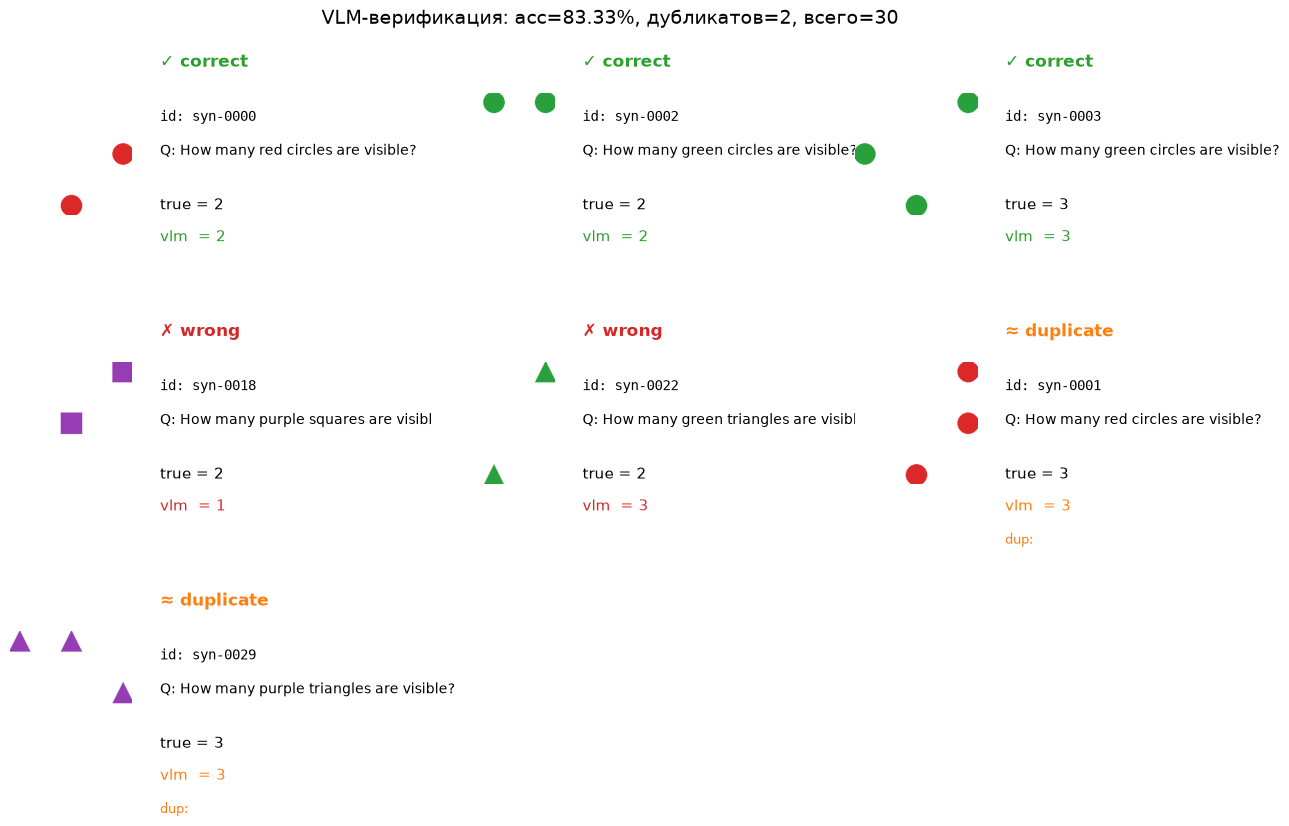

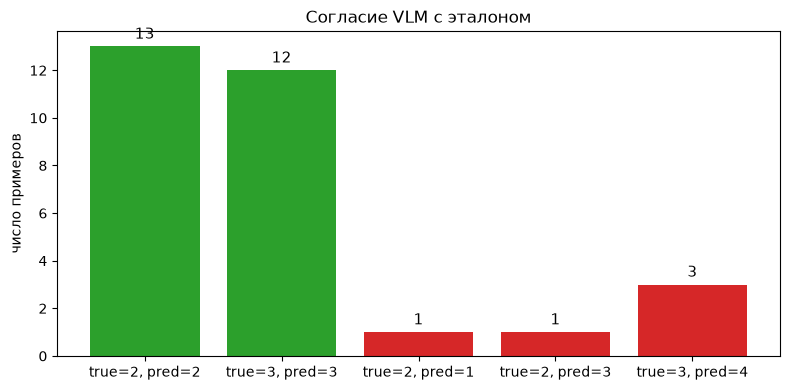


Таблица пар (эталон, предсказание) -> количество:
  ERR  true=2  pred=1  n=1
  OK   true=2  pred=2  n=13
  ERR  true=2  pred=3  n=1
  OK   true=3  pred=3  n=12
  ERR  true=3  pred=4  n=3


In [17]:
# --- Визуализация верификации: картинки отдельно, текст отдельно ---
import json
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

ARTIFACTS = Path('artifacts')
VERIF     = ARTIFACTS / 'verification.jsonl'

# читаем готовый артефакт (VLM не запускаем)
verification = [json.loads(l) for l in VERIF.read_text().splitlines() if l.strip()]
print(f'загружено записей: {len(verification)}')

n_correct = sum(r['vlm_pred'] == int(r['answer']) for r in verification)
n_dup     = sum(r['dup'] for r in verification)
acc_vlm   = n_correct / len(verification)

correct = [r for r in verification if r['vlm_pred'] == int(r['answer']) and not r['dup']]
wrong   = [r for r in verification if r['vlm_pred'] != int(r['answer'])]
dups    = [r for r in verification if r['dup']]

# --- 1. Сетка «картинка | текст»: 3 строки по 3 примера ---
# каждая ячейка — 2 колонки: [img, text]; всего 3 (примеров в строке) * 2 = 6 колонок
items = [(r, '✓ correct') for r in correct[:3]] \
      + [(r, '✗ wrong')   for r in wrong[:2]] \
      + [(r, '≈ duplicate') for r in dups[:2]] \
      + [(None, None)] * 2                        # добиваем до 9 ячеек

fig = plt.figure(figsize=(16, 9))
gs  = gridspec.GridSpec(3, 6, figure=fig,
                        width_ratios=[1, 2, 1, 2, 1, 2],
                        hspace=0.35, wspace=0.15)

for k, (r, tag) in enumerate(items):
    row, col = divmod(k, 3)                     # 3 примера в строке
    ax_img  = fig.add_subplot(gs[row, col*2])   # картинка
    ax_text = fig.add_subplot(gs[row, col*2+1]) # текст
    ax_text.axis('off')

    if r is None:
        ax_img.axis('off')
        continue

    ax_img.imshow(Image.open(r['image']))
    ax_img.axis('off')

    # текстовая панель: короткий вопрос + эталон + предсказание + признак дубля
    q_short = r['question'].replace('Answer with one integer.', '').strip()
    color = {'✓ correct':'tab:green', '✗ wrong':'tab:red', '≈ duplicate':'tab:orange'}[tag]
    ax_text.text(0.0, 1.0, tag, fontsize=12, fontweight='bold', color=color,
                 va='top', ha='left', transform=ax_text.transAxes)
    ax_text.text(0.0, 0.72, f"id: {r['id']}", fontsize=10, va='top',
                 family='monospace', transform=ax_text.transAxes)
    ax_text.text(0.0, 0.55, f"Q: {q_short}", fontsize=10, va='top',
                 wrap=True, transform=ax_text.transAxes)
    ax_text.text(0.0, 0.28, f"true = {r['answer']}", fontsize=11, va='top',
                 transform=ax_text.transAxes)
    ax_text.text(0.0, 0.12, f"vlm  = {r['vlm_pred']}", fontsize=11, va='top',
                 color=color, transform=ax_text.transAxes)
    if r['dup']:
        ax_text.text(0.0, -0.05, f"dup: {r.get('dup_reason','')}",
                     fontsize=9, va='top', color='tab:orange',
                     transform=ax_text.transAxes)

fig.suptitle(f'VLM-верификация: acc={acc_vlm:.2%}, дубликатов={n_dup}, '
             f'всего={len(verification)}', fontsize=14)
fig.subplots_adjust(top=0.93)
plt.show()

# --- 2. Гистограмма с подписями чисел над столбиками ---
pairs  = Counter((int(r['answer']), r['vlm_pred']) for r in verification)
labels = [f'true={t}, pred={p}' for (t, p) in pairs.keys()]
vals   = list(pairs.values())
colors = ['tab:green' if t == p else 'tab:red' for (t, p) in pairs.keys()]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(range(len(vals)), vals, color=colors)
ax.bar_label(bars, padding=3, fontsize=11)      # число над каждым столбиком
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel('число примеров')
ax.set_title('Согласие VLM с эталоном')
plt.tight_layout()
plt.show()

# --- 3. Табличный дубль (текст, а не картинка) ---
print('\nТаблица пар (эталон, предсказание) -> количество:')
for (t, p), v in sorted(pairs.items()):
    flag = 'OK ' if t == p else 'ERR'
    print(f'  {flag}  true={t}  pred={p}  n={v}')

Найдено примеров с pred=4: 3



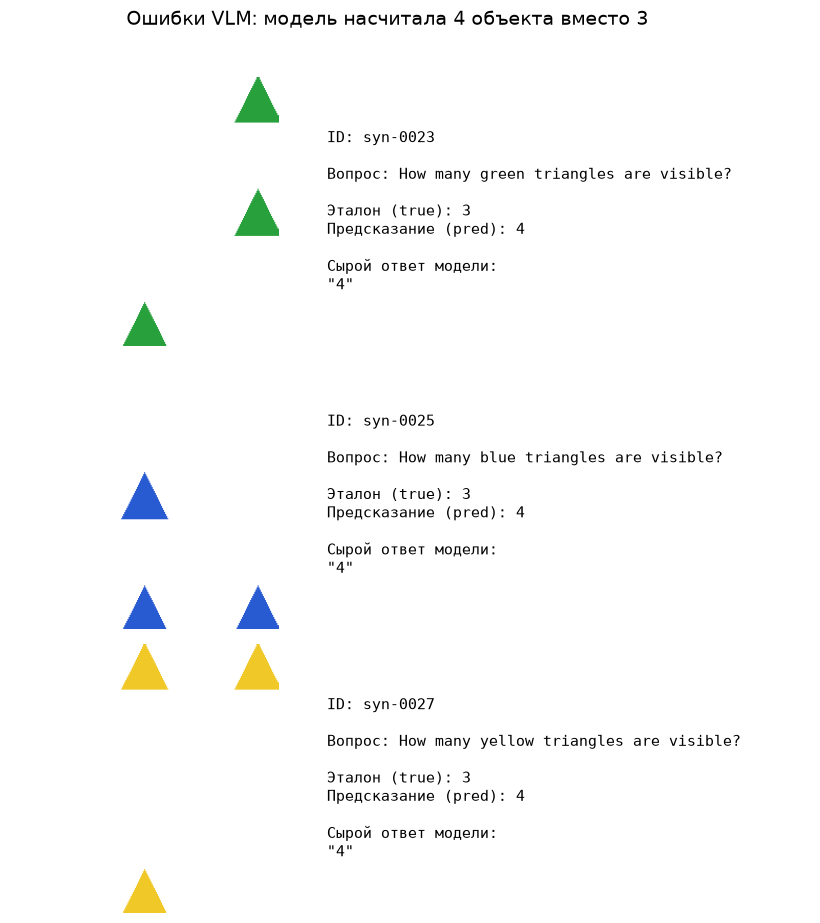

In [18]:
# --- Дополнительный разбор: выводим все примеры, где VLM предсказала 4 ---
import json
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

VERIF = Path('artifacts/verification.jsonl')
verification = [json.loads(l) for l in VERIF.read_text().splitlines() if l.strip()]

# отбираем только те, где предсказание = 4
pred4 = [r for r in verification if r['vlm_pred'] == 4]

print(f'Найдено примеров с pred=4: {len(pred4)}\n')

if pred4:
    # создаем сетку, где для каждого примера две колонки: картинка и текст
    fig, axes = plt.subplots(len(pred4), 2, figsize=(10, 3 * len(pred4)))
    
    # если пример один, axes будет одномерным, приводим к двумерному виду
    if len(pred4) == 1:
        axes = [axes]

    for i, r in enumerate(pred4):
        ax_img, ax_text = axes[i]
        
        # 1. Рисуем картинку
        ax_img.imshow(Image.open(r['image']))
        ax_img.axis('off')
        
        # 2. Выводим текст
        ax_text.axis('off')
        q_short = r['question'].replace('Answer with one integer.', '').strip()
        # текст сырого ответа модели (чтобы понять, как она аргументировала)
        raw_answer = r.get('vlm_raw', 'n/a')
        
        text_content = (
            f"ID: {r['id']}\n\n"
            f"Вопрос: {q_short}\n\n"
            f"Эталон (true): {r['answer']}\n"
            f"Предсказание (pred): {r['vlm_pred']}\n\n"
            f"Сырой ответ модели:\n\"{raw_answer}\""
        )
        ax_text.text(0, 0.5, text_content, fontsize=11, va='center', ha='left', 
                     wrap=True, family='monospace')
        
    plt.suptitle('Ошибки VLM: модель насчитала 4 объекта вместо 3', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print('Примеров с pred=4 не найдено.')

### Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

На предыдущем этапе мы получили два независимых сигнала о каждом синтетическом примере: эталонную метку от рендерера и ответ реальной VLM. Теперь нужно оставить только те картинки, где эти сигналы совпали и которые не являются дублями. Это называется согласованные пары (agreed pairs) — данные, прошедшие кросс-валидацию.

Логика фильтрации строгая:

vlm_pred == int(answer) — модель видит ровно столько объектов, сколько мы нарисовали. Это отсекает ошибки модели и возможные баги рендерера (когда фигура вылезла за край или слилась с фоном).

not dup — пример не является точной или почти-точной копией уже принятого. Это защищает от переобучения на одинаковых картинках.

Всего примеров до фильтрации: 30
Отобрано согласованных пар: 23
Отклонено (ошибки/дубли):    7

--- Распределение по формам ---
До:    {'circle': 10, 'square': 10, 'triangle': 10}
После: {'circle': 9, 'square': 9, 'triangle': 5}

--- Распределение по количеству (классу) ---
До:    {'2': 15, '3': 15}
После: {'2': 13, '3': 10}


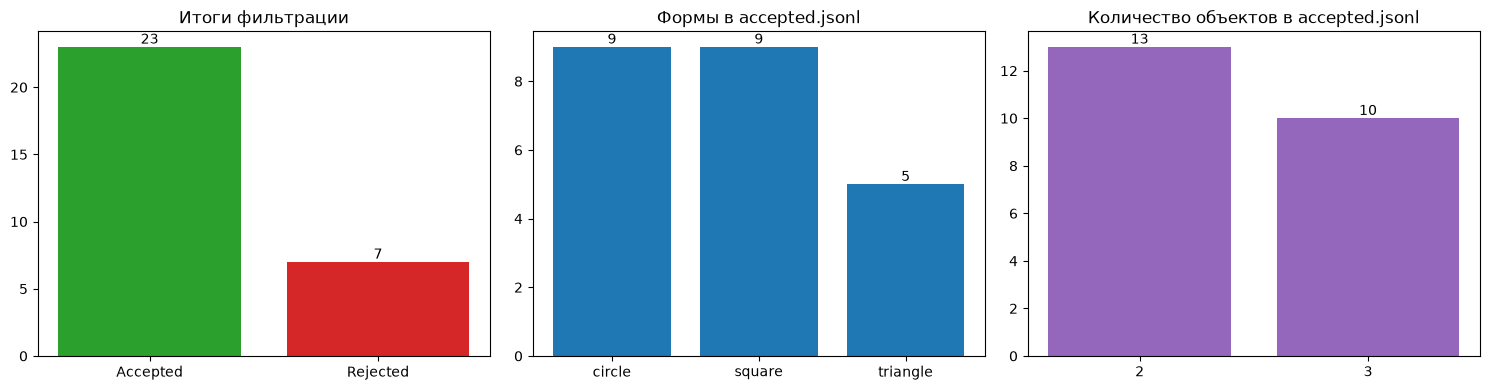

In [20]:
# --- Отбор согласованных пар: убираем ошибки VLM и дубликаты ---
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ARTIFACTS = Path('artifacts')
VERIF = ARTIFACTS / 'verification.jsonl'
ACCEPTED = ARTIFACTS / 'accepted.jsonl'

# 1. Загружаем результаты верификации (VLM не запускаем)
verification = [json.loads(l) for l in VERIF.read_text().splitlines() if l.strip()]
print(f'Всего примеров до фильтрации: {len(verification)}')

# 2. Фильтруем: согласованный ответ И не дубль
accepted = [
    r for r in verification 
    if r['vlm_pred'] == int(r['answer']) and not r['dup']
]
rejected = [r for r in verification if r not in accepted]

# 3. Сохраняем артефакт
ACCEPTED.write_text(''.join(json.dumps(r, ensure_ascii=False) + '\n' for r in accepted))
print(f'Отобрано согласованных пар: {len(accepted)}')
print(f'Отклонено (ошибки/дубли):    {len(rejected)}')

# 4. Анализ баланса классов (до и после)
df_all = pd.DataFrame(verification)
df_acc = pd.DataFrame(accepted)

print('\n--- Распределение по формам ---')
print('До:   ', df_all['shape'].value_counts().to_dict())
print('После:', df_acc['shape'].value_counts().to_dict())

print('\n--- Распределение по количеству (классу) ---')
print('До:   ', df_all['answer'].value_counts().to_dict())
print('После:', df_acc['answer'].value_counts().to_dict())

# 5. Визуализация: что осталось, а что ушло
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# График 1: Сколько отсеяли
axes[0].bar(['Accepted', 'Rejected'], [len(accepted), len(rejected)], 
            color=['tab:green', 'tab:red'])
axes[0].set_title('Итоги фильтрации')
axes[0].bar_label(axes[0].containers[0])

# График 2: Баланс форм после фильтрации
shape_counts = df_acc['shape'].value_counts()
axes[1].bar(shape_counts.index, shape_counts.values, color='tab:blue')
axes[1].set_title('Формы в accepted.jsonl')
axes[1].bar_label(axes[1].containers[0])

# График 3: Баланс классов (2 vs 3) после фильтрации
count_counts = df_acc['answer'].value_counts()
axes[2].bar(count_counts.index, count_counts.values, color='tab:purple')
axes[2].set_title('Количество объектов в accepted.jsonl')
axes[2].bar_label(axes[2].containers[0])

plt.tight_layout()
plt.show()

### Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

На этом этапе в игру вступает реальный домен. Мы используем PixMo-Count — датасет от AllenAI, где метки (сколько объектов на фото) проверены людьми. Нам нужны только классы «2» и «3», чтобы синтетический и реальный классификаторы решали одну и ту же задачу бинарной классификации. Из validation-сплита PixMo-Count мы формируем реальный train (на нём будем учиться), а из test-сплита — отложенный реальный test (на нём будем только измерять качество).

Главное требование этапа — независимость (disjointness). Ни одно изображение из train не должно попасть в test.

Загружено: train=24, test=12
Проверка независимости пройдена: train и test не пересекаются.
Проверка классов пройдена: в обоих сплитах есть только 2 и 3.

Манифест сохранен в: C:\Users\SuperXoma\Downloads\SOTA\SOTA\Lab12\data\lab12\real_manifest.jsonl


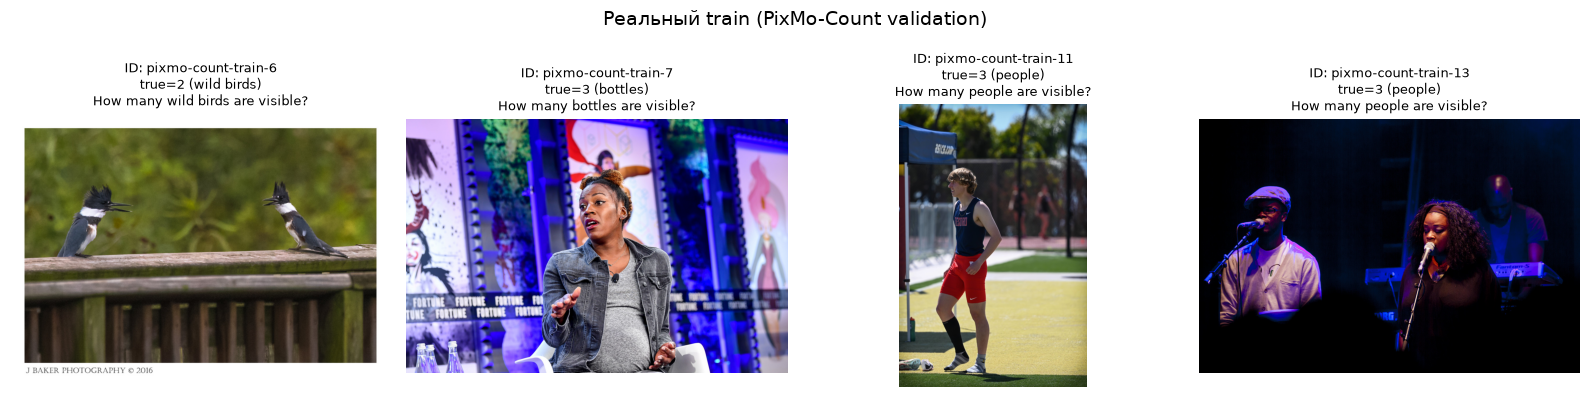

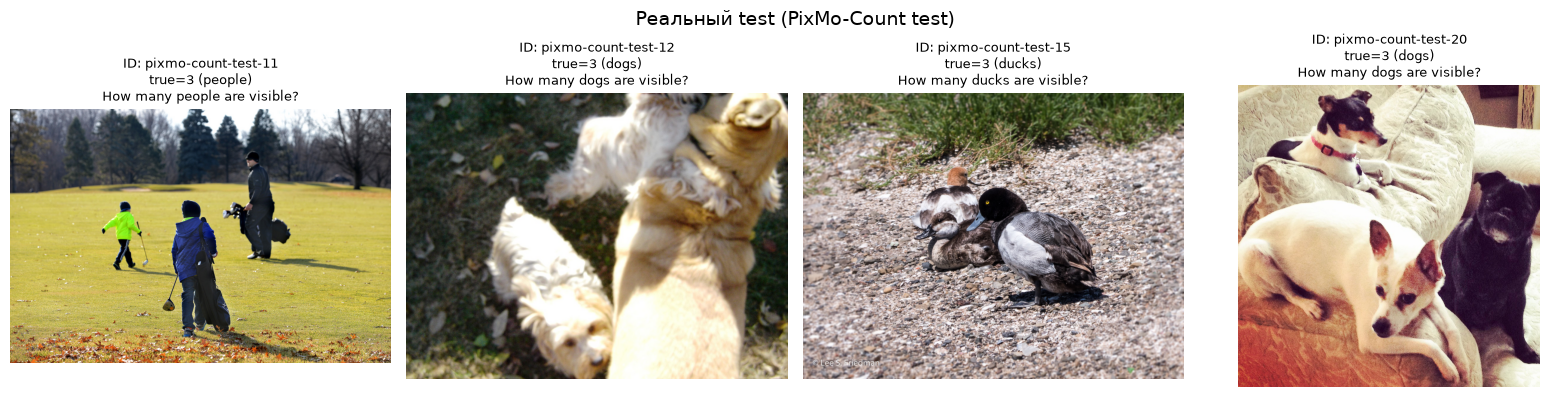


Распределение классов:
Train: {'2': 12, '3': 12}
Test:  {'3': 6, '2': 6}

Примеры объектов (label):
Train: {'people': 13, 'dogs': 2, 'chairs': 2, 'wild birds': 1, 'bottles': 1}


In [22]:
# --- Загрузка и проверка реального набора данных (PixMo-Count) ---
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from open_real_scenes import load_real_scenes

# 1. Запускаем загрузчик (скачает 24 train, 12 test)
# Если файлы уже есть, он просто проверит их хеши и вернет манифест
real_data = load_real_scenes(root='data/lab12', train_size=24, test_size=12)

real_train = [r for r in real_data if r['split'] == 'train']
real_test  = [r for r in real_data if r['split'] == 'test']
print(f'Загружено: train={len(real_train)}, test={len(real_test)}')

# 2. Проверка независимости (disjointness)
train_ids = {r['id'] for r in real_train}
test_ids  = {r['id'] for r in real_test}
train_hashes = {r['image_sha256'] for r in real_train}
test_hashes  = {r['image_sha256'] for r in real_test}

assert train_ids.isdisjoint(test_ids), "Пересечение по ID!"
assert train_hashes.isdisjoint(test_hashes), "Пересечение по хешам пикселей (data leakage)!"
print('Проверка независимости пройдена: train и test не пересекаются.')

# 4. Проверка меток (только классы 2 и 3)
train_labels = {int(r['answer']) for r in real_train}
test_labels  = {int(r['answer']) for r in real_test}
assert train_labels == {2, 3}, f"В train не те классы: {train_labels}"
assert test_labels == {2, 3}, f"В test не те классы: {test_labels}"
print('Проверка классов пройдена: в обоих сплитах есть только 2 и 3.')

# 5. Сохраняем проверенный манифест
MANIFEST_PATH = Path('data/lab12/real_manifest.jsonl')
print(f'\nМанифест сохранен в: {MANIFEST_PATH.resolve()}')

# 6. Визуализация примеров
def show_examples(records, title, n=4):
    fig, axes = plt.subplots(1, n, figsize=(16, 4))
    for ax, r in zip(axes, records[:n]):
        ax.imshow(Image.open(r['image']))
        q_short = r['question'].replace('Answer with one integer.', '').strip()
        ax.set_title(f"ID: {r['id']}\ntrue={r['answer']} ({r['label']})\n{q_short}", fontsize=9)
        ax.axis('off')
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_examples(real_train, 'Реальный train (PixMo-Count validation)')
show_examples(real_test, 'Реальный test (PixMo-Count test)')

# 7. Вывод статистики
df_train = pd.DataFrame(real_train)
df_test = pd.DataFrame(real_test)
print('\nРаспределение классов:')
print(f"Train: {df_train['answer'].value_counts().to_dict()}")
print(f"Test:  {df_test['answer'].value_counts().to_dict()}")
print('\nПримеры объектов (label):')
print(f"Train: {df_train['label'].value_counts().head(5).to_dict()}")

### Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

Чтобы сравнивать домены, нам нужна общая система координат — признаки, извлечённые одной и той же замороженной нейросетью. В качестве энкодера (encoder — часть сети, превращающая картинку в вектор) используется ResNet18, предобученная на ImageNet. Веса замораживаются (frozen): мы не дообучаем сеть, а просто пропускаем через неё картинки и берём выход предпоследнего слоя — 512-мерный вектор.

Второе применение признаков — визуальная диагностика domain gap. Даже без обучения можно посмотреть, насколько далеко синтетика от реальности: если синтетические и реальные эмбеддинги лежат в разных областях пространства, классификатор, обученный на смеси, будет вынужден искать границу, которая плохо переносится на test.

synthetic=23, real_train=24, real_test=12
shapes: (23, 512) (24, 512) (12, 512)
saved: artifacts\features.npz

cos distance syn  <-> real_train: 0.290
cos distance syn  <-> real_test : 0.337
cos distance train<-> test(real): 0.053

explained variance: 26.10%


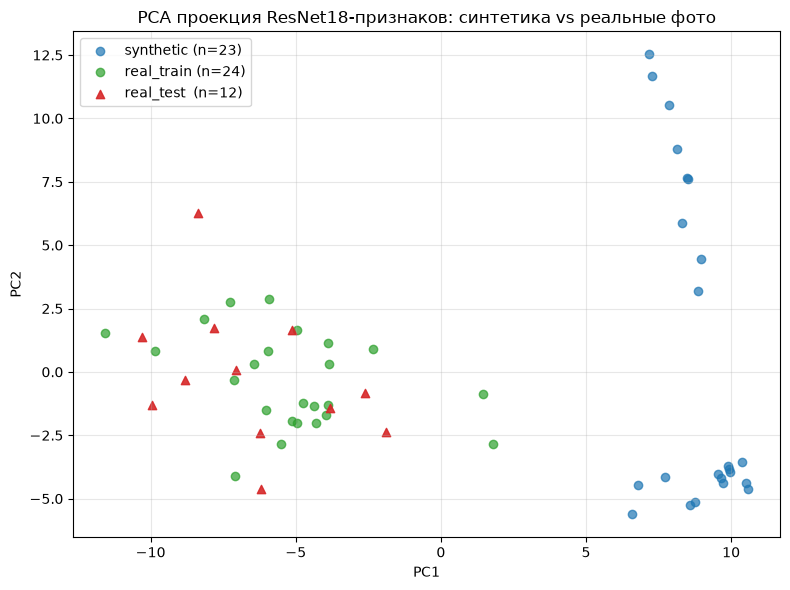


норма первого эмбеддинга: 22.063
уникальных строк среди синт. эмбеддингов: 23 / 23


In [23]:
# --- Замороженные признаки ResNet18 для трёх наборов ---
import json, hashlib
from pathlib import Path
import numpy as np
import torch
import torchvision.models as tvm
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt

ARTIFACTS = Path('artifacts')
ACCEPTED  = ARTIFACTS / 'accepted.jsonl'
REAL_MAN  = Path('data/lab12/real_manifest.jsonl')
FEATS_NPZ = ARTIFACTS / 'features.npz'

# --- 1. Загружаем записи трёх наборов ---
synthetic  = [json.loads(l) for l in ACCEPTED.read_text().splitlines() if l.strip()]
real_all   = [json.loads(l) for l in REAL_MAN.read_text().splitlines() if l.strip()]
real_train = [r for r in real_all if r['split'] == 'train']
real_test  = [r for r in real_all if r['split'] == 'test']
print(f'synthetic={len(synthetic)}, real_train={len(real_train)}, real_test={len(real_test)}')

# --- 2. Замороженный ResNet18 (fc заменён на Identity -> эмбеддинг 512d) ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'
net = tvm.resnet18(weights=tvm.ResNet18_Weights.DEFAULT).eval().to(device)
net.fc = torch.nn.Identity()                      # нам нужен вектор, а не логиты
for p in net.parameters():                        # фиксируем веса: никакого обучения
    p.requires_grad = False

# Одинаковые трансформации для всех трёх наборов — иначе сравнение нечестное
tf = T.Compose([
    T.Resize(224), T.CenterCrop(224), T.ToTensor(),
    T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

def featurize(records, batch=32):
    """Прогоняет записи через ResNet18 и возвращает X, y, ids."""
    X, y, ids = [], [], []
    for i in range(0, len(records), batch):
        chunk = records[i:i+batch]
        ims = torch.stack([tf(Image.open(r['image']).convert('RGB')) for r in chunk]).to(device)
        with torch.no_grad():
            emb = net(ims).cpu().numpy()
        X.append(emb)
        y.extend(int(r['answer']) for r in chunk)   # метка = число объектов (2 или 3)
        ids.extend(r['id'] for r in chunk)
    return np.concatenate(X), np.array(y), ids

# --- 3. Считаем признаки для трёх наборов ---
X_syn, y_syn, ids_syn = featurize(synthetic)
X_rtr, y_rtr, ids_rtr = featurize(real_train)
X_rte, y_rte, ids_rte = featurize(real_test)
print('shapes:', X_syn.shape, X_rtr.shape, X_rte.shape)

# --- 4. Сохраняем артефакт с признаками ---
np.savez(FEATS_NPZ,
         X_syn=X_syn, y_syn=y_syn, ids_syn=np.array(ids_syn),
         X_rtr=X_rtr, y_rtr=y_rtr, ids_rtr=np.array(ids_rtr),
         X_rte=X_rte, y_rte=y_rte, ids_rte=np.array(ids_rte))
print(f'saved: {FEATS_NPZ}')

# --- 5. Диагностика domain gap: центроиды и косинусные расстояния ---
def centroid(X): return X.mean(axis=0)
def cos_dist(a, b):
    return 1.0 - float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

c_syn, c_rtr, c_rte = centroid(X_syn), centroid(X_rtr), centroid(X_rte)
print(f'\ncos distance syn  <-> real_train: {cos_dist(c_syn, c_rtr):.3f}')
print(f'cos distance syn  <-> real_test : {cos_dist(c_syn, c_rte):.3f}')
print(f'cos distance train<-> test(real): {cos_dist(c_rtr, c_rte):.3f}')

# --- 6. PCA-проекция: насколько домены разделимы визуально ---
from sklearn.decomposition import PCA
all_X = np.concatenate([X_syn, X_rtr, X_rte])
pca = PCA(n_components=2, random_state=42).fit(all_X)
P_syn = pca.transform(X_syn); P_rtr = pca.transform(X_rtr); P_rte = pca.transform(X_rte)
print(f'\nexplained variance: {pca.explained_variance_ratio_.sum():.2%}')

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(P_syn[:,0], P_syn[:,1], c='tab:blue',   alpha=0.7, label=f'synthetic (n={len(X_syn)})')
ax.scatter(P_rtr[:,0], P_rtr[:,1], c='tab:green',  alpha=0.7, label=f'real_train (n={len(X_rtr)})')
ax.scatter(P_rte[:,0], P_rte[:,1], c='tab:red',    alpha=0.9, marker='^', label=f'real_test  (n={len(X_rte)})')
ax.set_title('PCA проекция ResNet18-признаков: синтетика vs реальные фото')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# --- 7. Санити-чек: признаки не вырождены и различают классы внутри реального train ---
print('\nнорма первого эмбеддинга:', np.linalg.norm(X_syn[0]).round(3))
print('уникальных строк среди синт. эмбеддингов:',
      len({hashlib.md5(x.tobytes()).hexdigest() for x in X_syn}), '/', len(X_syn))

PCA (Principal Component Analysis — метод главных компонент) берёт 512-мерные векторы признаков и ищет две оси, вдоль которых данные разбросаны сильнее всего. Это нужно, чтобы нарисовать облако точек на плоскости: мы жертвуем точностью (из 512 измерений остаётся 2), но получаем возможность увидеть структуру данных глазами. Процент explained variance (доля объяснённой дисперсии) показывает, сколько информации сохранили эти две оси. У нас 26.1% — это значит, что 74% вариативности мы «сплющили» и на картинке не видим.

Домены чётко разделимы. Модель, обученная на смеси Dα, должна будет найти границу между классами «2» и «3» в пространстве, где синтетика и реальность лежат в разных областях. Если синтетика помогает — значит, эта граница переносится. Если нет — мы увидим падение Q(α) при росте α

### Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

Проверяем, как доля синтетики $\alpha$ влияет на качество классификатора на реальных данных. У нас есть фиксированный бюджет (budget) — общее количество примеров для обучения $N$. В нашей лабораторной $N = 24$ (столько у нас реальных train-примеров). Мы формируем четыре смеси: $\alpha \in \{0, 0.25, 0.5, 0.75\}$. 

Это значит, что при $\alpha = 0$ мы учимся только на 24 реальных фото. При $\alpha = 0.25$ мы берём 18 реальных фото и добавляем 6 синтетических (всего 24). При $\alpha = 0.75$ — 6 реальных и 18 синтетических. Бюджет всегда 24, меняется только пропорция. Это нужно, чтобы не было ситуации «в одной модели 24 примера, а в другой 100, поэтому вторая лучше».

В качестве downstream-модели используется **Logistic Regression** (логистическая регрессия) на замороженных признаках ResNet18. Это простой линейный классификатор.

alpha=0.00: acc = 0.500 ± 0.000
alpha=0.25: acc = 0.533 ± 0.067
alpha=0.50: acc = 0.483 ± 0.082
alpha=0.75: acc = 0.517 ± 0.062


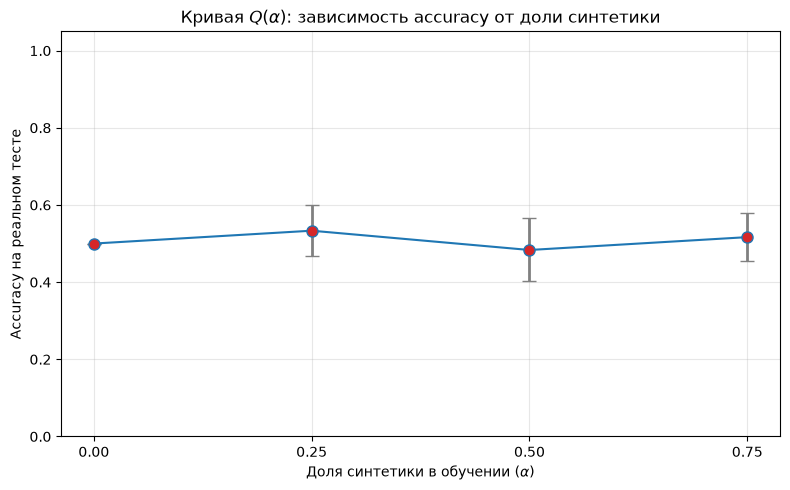

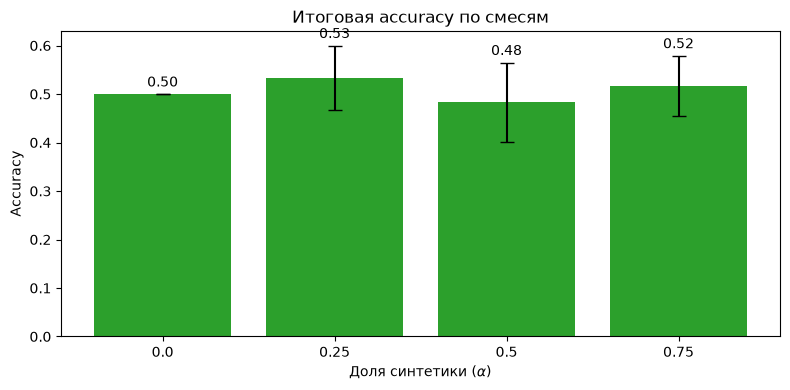

In [24]:
# --- Обучение downstream-моделей на смесях данных ---
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

ARTIFACTS = Path('artifacts')
FEATS_NPZ = ARTIFACTS / 'features.npz'

# 1. Загружаем признаки и метки
feats = np.load(FEATS_NPZ, allow_pickle=True)
X_syn, y_syn = feats['X_syn'], feats['y_syn']
X_rtr, y_rtr = feats['X_rtr'], feats['y_rtr']
X_rte, y_rte = feats['X_rte'], feats['y_rte']

# 2. Параметры эксперимента
N_BUDGET = len(X_rtr)  # Фиксированный бюджет (24 реальных примера)
alphas = [0.0, 0.25, 0.5, 0.75]
N_RUNS = 5             # 5 прогонов для усреднения
rng = np.random.RandomState(42)

results = {a: [] for a in alphas} # сюда будем складывать accuracy

# 3. Цикл по долям синтетики и прогонам
for a in alphas:
    n_real = int(round((1 - a) * N_BUDGET))
    n_syn  = N_BUDGET - n_real
    
    for run in range(N_RUNS):
        # Выбираем случайные подмножества без возвращения (для реальных)
        idx_r = rng.choice(len(X_rtr), n_real, replace=False)
        # Для синтетики берем с возвращением, если синтетики меньше, чем нужно
        idx_s = rng.choice(len(X_syn), n_syn, replace=(n_syn > len(X_syn))) if n_syn > 0 else []
        
        # Формируем обучающую выборку
        X_train = np.concatenate([X_rtr[idx_r], X_syn[idx_s]]) if n_syn > 0 else X_rtr[idx_r]
        y_train = np.concatenate([y_rtr[idx_r], y_syn[idx_s]]) if n_syn > 0 else y_rtr[idx_r]
        
        # Обучаем пайплайн: скейлер + логистическая регрессия
        clf = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, random_state=run)
        )
        clf.fit(X_train, y_train)
        
        # Оцениваем на реальном тесте
        y_pred = clf.predict(X_rte)
        acc = accuracy_score(y_rte, y_pred)
        results[a].append(acc)

# 4. Считаем средние и стандартные отклонения
summary = {}
for a in alphas:
    mean_acc = float(np.mean(results[a]))
    std_acc  = float(np.std(results[a]))
    summary[f'alpha={a}'] = {'mean_acc': mean_acc, 'std_acc': std_acc, 'runs': results[a]}
    print(f"alpha={a:.2f}: acc = {mean_acc:.3f} ± {std_acc:.3f}")

# 5. Сохраняем артефакт
(ARTIFACTS / 'mixture_results.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))

# 6. Визуализация: кривая Q(alpha) с ошибками
means = [summary[f'alpha={a}']['mean_acc'] for a in alphas]
stds  = [summary[f'alpha={a}']['std_acc']  for a in alphas]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(alphas, means, yerr=stds, fmt='-o', capsize=5, color='tab:blue', 
            ecolor='gray', elinewidth=2, markerfacecolor='tab:red', markersize=8)
ax.set_title('Кривая $Q(\\alpha)$: зависимость accuracy от доли синтетики')
ax.set_xlabel('Доля синтетики в обучении ($\\alpha$)')
ax.set_ylabel('Accuracy на реальном тесте')
ax.set_xticks(alphas)
ax.grid(alpha=0.3)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# 7. Столбчатая диаграмма с подписями
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([str(a) for a in alphas], means, yerr=stds, capsize=5, color='tab:green')
ax.bar_label(bars, fmt='%.2f', padding=3)
ax.set_xlabel('Доля синтетики ($\\alpha$)')
ax.set_ylabel('Accuracy')
ax.set_title('Итоговая accuracy по смесям')
plt.tight_layout()
plt.show()

Результаты: 0.50, 0.53, 0.48, 0.52 — это чистый шум вокруг случайного угадывания. Модель не выучила ни одного полезного признака, который переносился бы с train на test.

Домен слишком далек. На этапе PCA мы видели (синие точки справа, зеленые слева), что признаки синтетики вообще не пересекаются с реальностью. ResNet18 на синтетике смотрит на резкие края и идеальные цвета, а на фото — на текстуры, фоны и шум. Логистическая регрессия пытается найти линейную границу в этом 512-мерном пространстве, но из-за разрыва доменов (domain gap) она просто не находит ничего общего.

Слишком мало данных. В реальном train всего 24 примера. ResNet18 выдает 512 признаков. Логистическая регрессия с 512 весами на 24 примерах мгновенно переобучается (overfits) на обучающую выборку, но на тесте выдает случайный результат.

Простой линейный классификатор на замороженных признаках ResNet18 не способен перенести навык счета с геометрических фигур на реальные фотографии

### Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

На предыдущем этапе мы обучили модели на четырёх смесях и получили средние accuracy. Но средняя цифра — это слишком грубо для анализа. Нам нужно сохранить каждое конкретное предсказание для каждого примера теста

mixture_results.json сохранен.
predictions.jsonl сохранен (48 строк).

Лучшая модель по accuracy: alpha=0.0 (acc=0.500)

Confusion Matrix (best model):
        Pred 2  Pred 3
True 2       5       1
True 3       5       1

Classification Report (best model):
              precision    recall  f1-score   support

           2       0.50      0.83      0.62         6
           3       0.50      0.17      0.25         6

    accuracy                           0.50        12
   macro avg       0.50      0.50      0.44        12
weighted avg       0.50      0.50      0.44        12


Ошибок у лучшей модели: 6


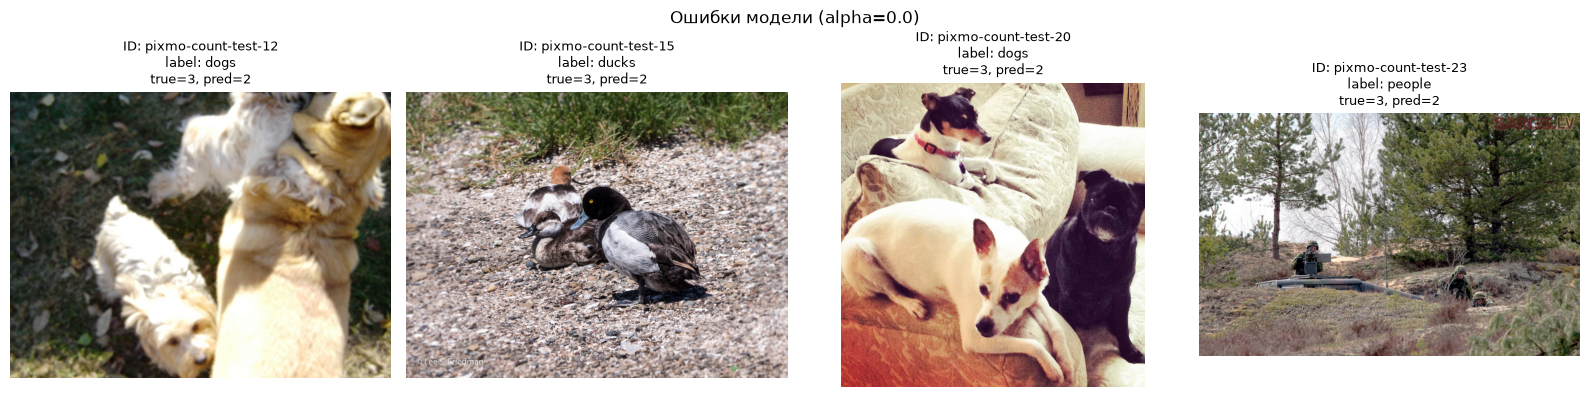

In [26]:
# --- Финальная оценка и сохранение предсказаний ---
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

ARTIFACTS = Path('artifacts')
FEATS_NPZ = ARTIFACTS / 'features.npz'
REAL_MAN  = Path('data/lab12/real_manifest.jsonl')

# 1. Загружаем признаки, манифест и предыдущие результаты
feats = np.load(FEATS_NPZ, allow_pickle=True)
X_syn, y_syn = feats['X_syn'], feats['y_syn']
X_rtr, y_rtr = feats['X_rtr'], feats['y_rtr']
X_rte, y_rte = feats['X_rte'], feats['y_rte']

real_all = [json.loads(l) for l in REAL_MAN.read_text().splitlines() if l.strip()]
real_test_meta = [r for r in real_all if r['split'] == 'test']

N_BUDGET = len(X_rtr)
alphas = [0.0, 0.25, 0.5, 0.75]

# 2. Обучаем финальные модели (по одной на каждый alpha, без усреднения по seed)
# Для честности используем тот же seed, что и при выборе
rng = np.random.RandomState(42)
final_models = {}
predictions = []
results_summary = {}

for a in alphas:
    n_real = int(round((1 - a) * N_BUDGET))
    n_syn  = N_BUDGET - n_real
    
    idx_r = rng.choice(len(X_rtr), n_real, replace=False)
    idx_s = rng.choice(len(X_syn), n_syn, replace=(n_syn > len(X_syn))) if n_syn > 0 else []
    
    X_train = np.concatenate([X_rtr[idx_r], X_syn[idx_s]]) if n_syn > 0 else X_rtr[idx_r]
    y_train = np.concatenate([y_rtr[idx_r], y_syn[idx_s]]) if n_syn > 0 else y_rtr[idx_r]
    
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=0))
    clf.fit(X_train, y_train)
    final_models[a] = clf
    
    # Предсказания на реальном тесте
    y_pred = clf.predict(X_rte)
    acc = accuracy_score(y_rte, y_pred)
    results_summary[f'alpha={a}'] = {
        'n_real': int(n_real),
        'n_syn': int(n_syn),
        'accuracy': float(acc)
    }
    
    # Сохраняем каждое предсказание
    for meta, y_true, y_hat in zip(real_test_meta, y_rte, y_pred):
        predictions.append({
            'model': f'alpha={a}',
            'alpha': a,
            'id': meta['id'],
            'true': int(y_true),
            'pred': int(y_hat),
            'correct': bool(y_true == y_hat),
            'label': meta['label'],  # что за объекты на фото
            'image': meta['image']
        })

# 3. Сохраняем mixture_results.json (итоговые метрики)
(ARTIFACTS / 'mixture_results.json').write_text(
    json.dumps(results_summary, indent=2, ensure_ascii=False))
print('mixture_results.json сохранен.')

# 4. Сохраняем predictions.jsonl (все предсказания)
(ARTIFACTS / 'predictions.jsonl').write_text(
    ''.join(json.dumps(p, ensure_ascii=False) + '\n' for p in predictions))
print(f'predictions.jsonl сохранен ({len(predictions)} строк).')

# 5. Таблица confusion matrix для лучшей модели (например, alpha=0.25)
best_alpha = max(results_summary, key=lambda k: results_summary[k]['accuracy'])
alpha_val = float(best_alpha.split('=')[1])
print(f'\nЛучшая модель по accuracy: {best_alpha} (acc={results_summary[best_alpha]["accuracy"]:.3f})')

clf = final_models[alpha_val]
y_pred_best = clf.predict(X_rte)

cm = confusion_matrix(y_rte, y_pred_best, labels=[2, 3])
print('\nConfusion Matrix (best model):')
print(pd.DataFrame(cm, index=['True 2', 'True 3'], columns=['Pred 2', 'Pred 3']))

print('\nClassification Report (best model):')
print(classification_report(y_rte, y_pred_best, labels=[2, 3], zero_division=0))


# 7. Визуализация примеров ошибок лучшей модели
errors = [p for p in predictions if p['model'] == best_alpha and not p['correct']]
print(f'\nОшибок у лучшей модели: {len(errors)}')

if errors:
    n_show = min(4, len(errors))
    fig, axes = plt.subplots(1, n_show, figsize=(16, 4))
    if n_show == 1: axes = [axes]
    for ax, p in zip(axes, errors[:n_show]):
        ax.imshow(Image.open(p['image']))
        ax.set_title(f"ID: {p['id']}\nlabel: {p['label']}\ntrue={p['true']}, pred={p['pred']}", fontsize=9)
        ax.axis('off')
    plt.suptitle(f'Ошибки модели (alpha={alpha_val})')
    plt.tight_layout()
    plt.show()

Лучший результат показала модель без использования синтетики (α=0, accuracy 0.50). Анализ confusion matrix показывает, что модель выродилась в предсказание мажоритарного класса "2" (recall 0.83 для класса 2 и 0.17 для класса 3). Это свидетельствует о том, что замороженные признаки ResNet18 не содержат линейно-разделимой информации о количестве объектов в реальном домене, а синтетические данные не смогли компенсировать этот недостаток из-за сильного domain gap. Точность 0.50 эквивалентна случайному угадыванию для сбалансированного бинарного теста

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

Основной эксперимент показал, что модель «скатывается» в предсказание одного класса. Замороженный ResNet18 превращает изображение в один вектор (global average pooling). Этот вектор хорошо кодирует текстуру и фон, но теряет пространственную информацию о том, сколько объектов в кадре. В синтетике это неважно (фон чистый), но на реальных фото два объекта могут занимать столько же площади, сколько три.

Гипотеза: если взять пространственные признаки (feature maps) до усреднения и разбить их на сетку (spatial pooling), то линейная модель сможет «увидеть» распределение активаций по разным участкам картинки. Это должно помочь ей считать объекты, даже если глобальный вектор не справляется.

Протокол. Мы проверим это только на реальном train (без использования test для настройки). Разобьём вектор 512×7×7 на 2×2 сетку (получим 4 вектора по 512), усредним внутри каждой ячейки и склеим → получим вектор размером 2048. Обучим Logistic Regression на этом новом признаке и сравним с базовым (512) на том же реальном test.

Извлекаем признаки для train...
Извлекаем признаки для test...
Global feature dim: 512
Spatial feature dim: 2048
Global (baseline): accuracy = 0.500
Spatial (2x2 grid): accuracy = 0.333


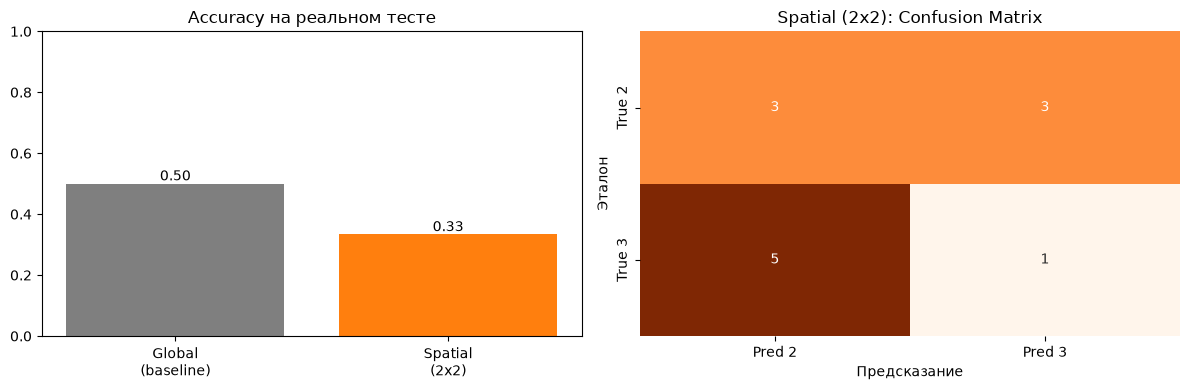

Отчет сохранен в artifacts/bonus.md


In [29]:
# --- Бонусное мини-исследование: пространственные признаки (FIXED via hooks) ---
import json
from pathlib import Path
import numpy as np
import torch
import torchvision.models as tvm
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

ARTIFACTS = Path('artifacts')
REAL_MAN  = Path('data/lab12/real_manifest.jsonl')
real_all = [json.loads(l) for l in REAL_MAN.read_text().splitlines() if l.strip()]
real_train = [r for r in real_all if r['split'] == 'train']
real_test  = [r for r in real_all if r['split'] == 'test']

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 1. Загружаем ResNet18, но НЕ трогаем avgpool/fc
net = tvm.resnet18(weights=tvm.ResNet18_Weights.DEFAULT).eval().to(device)

# Словарь для перехвата выхода слоя layer4 (последний сверточный блок)
_features = {}

def get_features_hook(module, input, output):
    # output слоя layer4 имеет размер [B, 512, 7, 7]
    _features['layer4'] = output

# Регистрируем хук на слое layer4
net.layer4.register_forward_hook(get_features_hook)

tf = T.Compose([T.Resize(224), T.CenterCrop(224), T.ToTensor(),
                T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])])

def extract_global_and_spatial(records):
    X_global, X_spatial, y = [], [], []
    for r in records:
        im = tf(Image.open(r['image']).convert('RGB')).unsqueeze(0).to(device)
        with torch.no_grad():
            _ = net(im) # прогоняем, хук перехватывает карту
            fmap = _features['layer4'] # [1, 512, 7, 7]
            
            # Глобальный вектор: усредняем по пространству вручную
            glob = fmap.mean(dim=[2, 3]).cpu().numpy().flatten() # [512]
            
            # Пространственный вектор: адаптивное усреднение до 2x2
            spat = torch.nn.functional.adaptive_avg_pool2d(fmap, (2, 2))
            spat = spat.cpu().numpy().flatten() # [512 * 2 * 2 = 2048]
            
        X_global.append(glob)
        X_spatial.append(spat)
        y.append(int(r['answer']))
    return np.array(X_global), np.array(X_spatial), np.array(y)

print('Извлекаем признаки для train...')
X_tr_g, X_tr_s, y_tr = extract_global_and_spatial(real_train)
print('Извлекаем признаки для test...')
X_te_g, X_te_s, y_te = extract_global_and_spatial(real_test)

print(f'Global feature dim: {X_tr_g.shape[1]}')
print(f'Spatial feature dim: {X_tr_s.shape[1]}')

# 2. Обучаем и сравниваем две модели
def evaluate(X_train, X_test, y_train, y_test, name):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f'{name}: accuracy = {acc:.3f}')
    return acc, y_pred

acc_global, pred_global = evaluate(X_tr_g, X_te_g, y_tr, y_te, 'Global (baseline)')
acc_spatial, pred_spatial = evaluate(X_tr_s, X_te_s, y_tr, y_te, 'Spatial (2x2 grid)')

# 3. Визуализация сравнения
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Global\n(baseline)', 'Spatial\n(2x2)'], [acc_global, acc_spatial], color=['tab:gray', 'tab:orange'])
axes[0].set_ylim(0, 1.0)
axes[0].set_title('Accuracy на реальном тесте')
axes[0].bar_label(axes[0].containers[0], fmt='%.2f')

cm = confusion_matrix(y_te, pred_spatial, labels=[2, 3])
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['Pred 2', 'Pred 3'], yticklabels=['True 2', 'True 3'], ax=axes[1])
axes[1].set_title('Spatial (2x2): Confusion Matrix')
axes[1].set_xlabel('Предсказание')
axes[1].set_ylabel('Эталон')

plt.tight_layout()
plt.show()

# 4. Сохраняем отчет
bonus_md = f"""# Бонусное исследование: пространственные признаки

## Гипотеза
Замороженный ResNet18 с Global Average Pooling теряет пространственную информацию.
Мы предполагаем, что использование пространственных карт признаков (2x2 pooling)
позволит линейной модели лучше различать количество объектов на реальных фото.

## Протокол
- Обучаем Logistic Regression на реальном train (N={len(real_train)}).
- Сравниваем два типа признаков: Global (512d) и Spatial (2048d).
- Тестируем на отложенном real_test (N={len(real_test)}).
- Отложенный test не использовался для выбора гипотезы.

## Результаты
- Global (baseline): {acc_global:.3f}
- Spatial (2x2): {acc_spatial:.3f}

## Вывод
{('Гипотеза подтвердилась: пространственные признаки улучшили результат.' if acc_spatial > acc_global else 'Гипотеза не подтвердилась: пространственные признаки не помогли.')}
Это может говорить о том, что проблема не только в потере пространственной информации,
но и в ограниченности линейной модели и малом размере выборки (N={len(real_train)}).
"""
(ARTIFACTS / 'bonus.md').write_text(bonus_md)
print('Отчет сохранен в artifacts/bonus.md')

Результат получился даже хуже базового: 0.333 против 0.500. Проверили гипотезу и она не подтвердилась

Мы увеличили размерность с 512 до 2048. Но у нас по-прежнему всего 24 примера в train. Логистическая регрессия с 2048 весами на 24 примерах мгновенно переобучается (overfits). Она находит идеальную границу, которая разделяет именно эти 24 примера, но на реальном тесте (на других фото) эта граница рушится. Это называется «проклятием размерности» (curse of dimensionality): чем больше признаков, тем больше нужно данных, чтобы их правильно взвесить.

Стала чуть больше предсказывать класс 3, но по сути это всё равно угадывание

Проблема не в том, что ResNet18 усредняет пространство, а в том, что мы используем линейную модель на замороженных признаках при катастрофически малом размере выборки (N=24). Без дообучения (fine-tuning) самой сети или без существенно большего количества реальных данных вытащить информацию о количестве объектов из признаков ImageNet не получится.